In [1]:
import random

import numpy as np
import torch

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.use_deterministic_algorithms(True)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cpu")

In [ ]:
from torchvision import datasets, transforms
from torchvision.transforms import InterpolationMode, v2

TRAIN_DATA_PATH = "./data/train/"
TEST_DATA_PATH = "./data/test/"

mean=[0.485, 0.456, 0.406]
std=[0.229, 0.224, 0.225]

# transform_v2 = v2.Compose([
#     v2.Resize((200, 200), interpolation=InterpolationMode.BILINEAR),
#     v2.ToImage(),
#     v2.ToDtype(torch.float32, scale=True),
#     v2.Normalize(mean=mean, std=std),
# ])

transform_v2 = transforms.Compose([
    transforms.Resize((200, 200), interpolation=InterpolationMode.BILINEAR),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=mean,
        std=std,
    ),
])

training_data = datasets.ImageFolder(
    root=TRAIN_DATA_PATH,
    transform=transform_v2
)

test_data = datasets.ImageFolder(
    root=TEST_DATA_PATH,
    transform=transform_v2
)


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.0494049..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9980307..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.5005665].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.2914162].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.0182073..2.5179958].


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.0322802..2.3235295].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.0665298..2.3611329].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.0665298..2.4831376].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.622571].


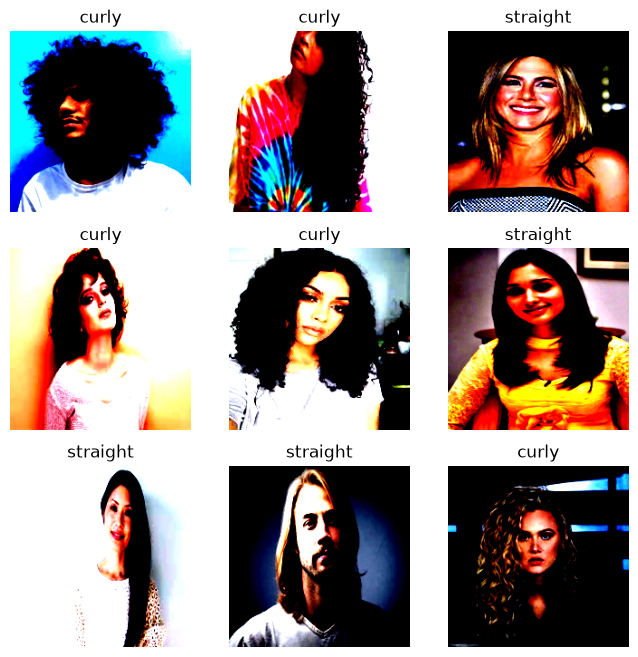

In [11]:
import matplotlib.pyplot as plt

labels_map = {
    0: "curly",
    1: "straight",
}
figure = plt.figure(figsize=(8, 8))
cols, rows = 3, 3
for i in range(1, cols * rows + 1):
    sample_idx = torch.randint(len(training_data), (1,)).item()
    img, label = training_data[sample_idx]
    figure.add_subplot(rows, cols, i)
    plt.title(labels_map[label])
    plt.axis("off")
    plt.imshow(img.permute(1, 2, 0))
plt.show()


In [12]:
from torch.utils.data import DataLoader

loader_generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(
    training_data,
    batch_size=20,
    shuffle=True,
    num_workers=0,
    generator=loader_generator,
)
evaluation_loader = DataLoader(
    test_data,
    batch_size=20,
    shuffle=False,
    num_workers=0,
)

In [13]:
import torch.nn as nn


class HairModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=0)
        self.pool = nn.MaxPool2d(kernel_size=2)
        self.hidden = nn.Linear(32 * 99 * 99, 64)
        self.output = nn.Linear(64, 1)

    def forward(self, x):
        x = self.pool(nn.functional.relu(self.conv(x)))
        x = x.flatten(start_dim=1)
        x = nn.functional.relu(self.hidden(x))
        return self.output(x)

In [ ]:
device = torch.device("cpu")
model = HairModel().to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.002,
    momentum=0.8,
)

In [28]:
sum(p.numel() for p in model.parameters())

20073473

In [35]:
import json

history = {
    "train_loss": [],
    "train_accuracy": [],
    "evaluation_loss": [],
    "evaluation_accuracy": [],
}

def evaluate(model, loader):
    model.eval()
    total_loss = 0.0
    total_correct = 0.0
    total_examples = 0.0

    with torch.no_grad():
        for images, labels in loader:
            targets = labels.float().unsqueeze(1)
            logits = model(images)
            loss = criterion(logits, targets)
            predictions = torch.sigmoid(logits) >= 0.5
            
            batch_size = images.size(0)
            total_loss += loss.item() * batch_size
            total_correct += (predictions == targets.bool()).sum().item()
            total_examples += batch_size
    
    return total_loss / total_examples, total_correct / total_examples

for epoch in range(10):
    model.train()
    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    for images, labels in train_loader:
        targets = labels.float().unsqueeze(1)
        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, targets)
        loss.backward()
        optimizer.step()

        predictions = torch.sigmoid(logits) >= 0.5
        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        total_correct += (predictions == targets.bool()).sum().item()
        total_examples += batch_size
    
    train_loss = total_loss / total_examples
    train_accuracy = total_correct / total_examples
    evaluation_loss, evaluation_accuracy = evaluate(model, evaluation_loader)

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["evaluation_loss"].append(evaluation_loss)
    history["evaluation_accuracy"].append(evaluation_accuracy)

    print(
        f"Epoch {epoch + 1:02d}/10 | "
        f"train loss {train_loss:.4f}, accuracy {train_accuracy:.2%} | "
        f"evaluation loss {evaluation_loss:.4f}, accuracy {evaluation_accuracy:.2%}"
    )

with open("history_baseline.json", "w", encoding="utf-8") as file:
    json.dump(history, file, indent=2)

Epoch 01/10 | train loss 0.6228, accuracy 64.25% | evaluation loss 0.5958, accuracy 65.67%
Epoch 02/10 | train loss 0.5326, accuracy 73.00% | evaluation loss 0.5855, accuracy 64.68%
Epoch 03/10 | train loss 0.4804, accuracy 76.00% | evaluation loss 0.6115, accuracy 63.68%
Epoch 04/10 | train loss 0.4073, accuracy 80.88% | evaluation loss 0.6204, accuracy 70.65%
Epoch 05/10 | train loss 0.3618, accuracy 82.62% | evaluation loss 0.6119, accuracy 70.15%
Epoch 06/10 | train loss 0.3393, accuracy 85.12% | evaluation loss 0.6284, accuracy 70.15%
Epoch 07/10 | train loss 0.2486, accuracy 90.38% | evaluation loss 0.6358, accuracy 71.64%
Epoch 08/10 | train loss 0.1928, accuracy 93.25% | evaluation loss 0.6916, accuracy 70.65%
Epoch 09/10 | train loss 0.2243, accuracy 90.50% | evaluation loss 0.6577, accuracy 69.65%
Epoch 10/10 | train loss 0.0971, accuracy 97.50% | evaluation loss 0.7868, accuracy 67.16%


In [36]:
with open("history_baseline.json", "r", encoding="utf-8") as file:
    loaded_hist = json.load(file)

In [42]:
np.round(np.median(loaded_hist["train_accuracy"]), 2)

np.float64(0.84)

In [44]:
np.round(np.std(loaded_hist["train_loss"], ddof=0), 2)

np.float64(0.16)

In [45]:
train_transform_augmented = transforms.Compose([
    transforms.Resize((200, 200), interpolation=transforms.InterpolationMode.BILINEAR),
    transforms.RandomRotation(
        50,
        interpolation=transforms.InterpolationMode.NEAREST,
    ),
    transforms.RandomResizedCrop(
        200,
        scale=(0.9, 1.0),
        ratio=(0.9, 1.1),
        interpolation=transforms.InterpolationMode.BILINEAR,
    ),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])

In [47]:
training_data = datasets.ImageFolder(
    root=TRAIN_DATA_PATH,
    transform=train_transform_augmented
)

train_loader = DataLoader(
    training_data,
    batch_size=20,
    shuffle=True,
    num_workers=0,
    generator=loader_generator,
)

In [48]:
history = {
    "train_loss": [],
    "train_accuracy": [],
    "evaluation_loss": [],
    "evaluation_accuracy": [],
}

def evaluate(model, loader):
    model.eval()
    total_loss = 0.0
    total_correct = 0.0
    total_examples = 0.0

    with torch.no_grad():
        for images, labels in loader:
            targets = labels.float().unsqueeze(1)
            logits = model(images)
            loss = criterion(logits, targets)
            predictions = torch.sigmoid(logits) >= 0.5
            
            batch_size = images.size(0)
            total_loss += loss.item() * batch_size
            total_correct += (predictions == targets.bool()).sum().item()
            total_examples += batch_size
    
    return total_loss / total_examples, total_correct / total_examples

for epoch in range(10):
    model.train()
    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    for images, labels in train_loader:
        targets = labels.float().unsqueeze(1)
        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, targets)
        loss.backward()
        optimizer.step()

        predictions = torch.sigmoid(logits) >= 0.5
        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        total_correct += (predictions == targets.bool()).sum().item()
        total_examples += batch_size
    
    train_loss = total_loss / total_examples
    train_accuracy = total_correct / total_examples
    evaluation_loss, evaluation_accuracy = evaluate(model, evaluation_loader)

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["evaluation_loss"].append(evaluation_loss)
    history["evaluation_accuracy"].append(evaluation_accuracy)

    print(
        f"Epoch {epoch + 1:02d}/10 | "
        f"train loss {train_loss:.4f}, accuracy {train_accuracy:.2%} | "
        f"evaluation loss {evaluation_loss:.4f}, accuracy {evaluation_accuracy:.2%}"
    )

with open("history_augmented.json", "w", encoding="utf-8") as file:
    json.dump(history, file, indent=2)

Epoch 01/10 | train loss 0.6771, accuracy 62.50% | evaluation loss 0.5650, accuracy 73.63%
Epoch 02/10 | train loss 0.5893, accuracy 66.62% | evaluation loss 0.5537, accuracy 74.13%
Epoch 03/10 | train loss 0.5511, accuracy 73.00% | evaluation loss 0.6394, accuracy 67.16%
Epoch 04/10 | train loss 0.5359, accuracy 72.75% | evaluation loss 0.5332, accuracy 74.63%
Epoch 05/10 | train loss 0.5316, accuracy 72.12% | evaluation loss 0.5606, accuracy 72.14%
Epoch 06/10 | train loss 0.5151, accuracy 73.12% | evaluation loss 0.5564, accuracy 73.63%
Epoch 07/10 | train loss 0.5376, accuracy 71.75% | evaluation loss 0.5128, accuracy 74.13%
Epoch 08/10 | train loss 0.5186, accuracy 73.62% | evaluation loss 0.5219, accuracy 77.11%
Epoch 09/10 | train loss 0.4772, accuracy 74.25% | evaluation loss 0.6414, accuracy 70.15%
Epoch 10/10 | train loss 0.4629, accuracy 78.25% | evaluation loss 0.6139, accuracy 75.12%


In [49]:
with open("history_augmented.json", "r", encoding="utf-8") as file:
    loaded_hist = json.load(file)

In [53]:
np.round(np.mean(loaded_hist["evaluation_loss"]), 4)

np.float64(0.5698)

In [57]:
np.round(np.mean(loaded_hist["evaluation_accuracy"][5:]),2)

np.float64(0.74)